In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def euler_newton(force, times, xI, vI, m):
    xA = np.zeros(times.size)
    vA = np.zeros(times.size)
    xA[0] = xI
    vA[0] = vI
    for i in range(0,times.size-1):
        dt = times[i+1]-times[i]
        a = force(times[i], xA[i], vA[i]) / m
        vA[i+1] = vA[i] + a*dt
        xA[i+1] = xA[i] + vA[i+1]*dt
    return xA, vA

In [178]:
def osc(b,k,t,x,v):
    return -b*v - k*x

**1)**
Adding -kx term to the function  
Let*b* = 2, *k* = 3, and *m* = 10

In [179]:
t = np.linspace(0,60,300)
x,v = (euler_newton(lambda x,t,v: osc(2,3,x,t,v), t,10,0,10))

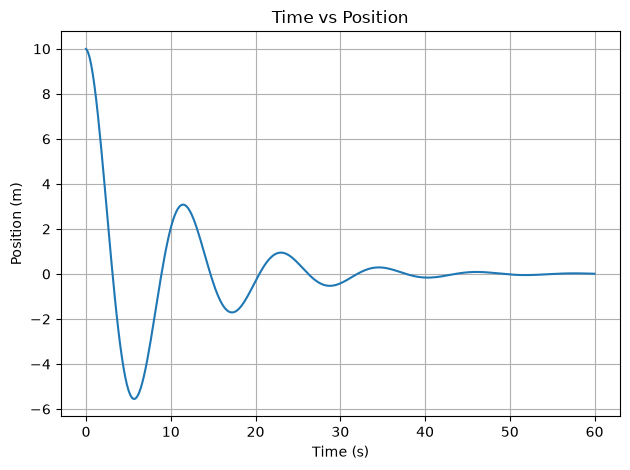

In [180]:
plt.plot(t,x)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Time vs Position")
plt.tight_layout()
plt.grid()
plt.show()

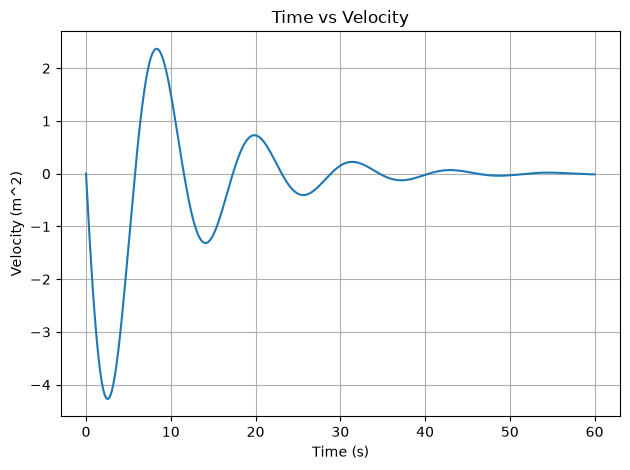

In [181]:
plt.plot(t,v)
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m^2)")
plt.title("Time vs Velocity")
plt.tight_layout()
plt.grid()
plt.show()

**2)** Graphing different types of oscillations

**Underdamped** ($\gamma$<2$\omega$<sub>0</sub>)  
Let *b* = 2, *k* = 20, and *m* = 10, starting from *x* = 10m

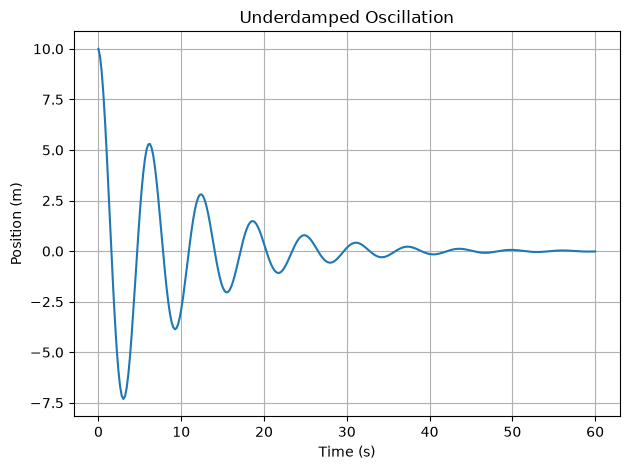

In [182]:
xU,vU = (euler_newton(lambda x,t,v: osc(2,10,x,t,v), t,10,0,10))
plt.plot(t,xU)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Underdamped Oscillation")
plt.tight_layout()
plt.grid()
plt.show()

**Overdamped** ($\gamma$>2$\omega$<sub>0</sub>)  
Let *b* = 20, *k* = 10, and *m* = 10, starting at *x* = 10m

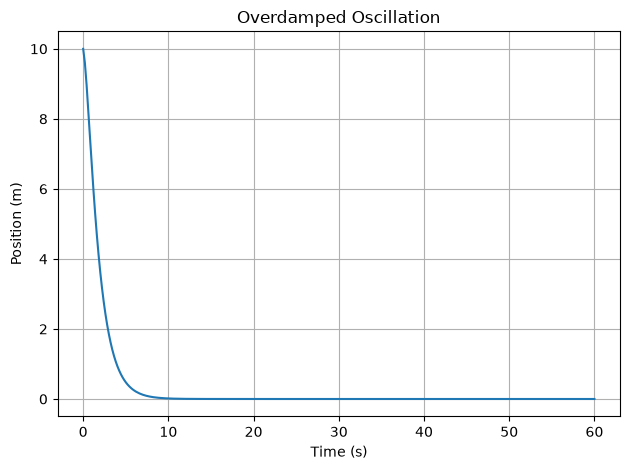

In [183]:
xO,vO = (euler_newton(lambda x,t,v: osc(20,10,x,t,v), t,10,0,10))
plt.plot(t,xO)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Overdamped Oscillation")
plt.tight_layout()
plt.grid()
plt.show()

**Crtically Damped** ($\gamma$ = 2$\omega$<sub>0</sub>)  
Let *b* = 20, *k* = 40, and *m* = 10, starting at *x* = 10m

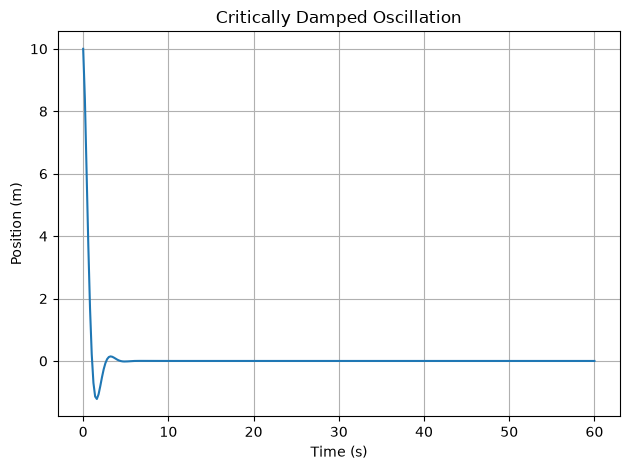

In [184]:
xO,vO = (euler_newton(lambda x,t,v: osc(20,40,x,t,v), t, 10, 0, 10))
plt.plot(t,xO)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Critically Damped Oscillation")
plt.tight_layout()
plt.grid()
plt.show()

**3)** Driving force *F(t)=F<sub>0</sub> cos $\omega$<sub>d</sub>t*  
Let *b* = 2, *k* = 20, *m* = 10, *F<sub>0</sub>* = 40 and *$\omega$<sub>d</sub>* = 5  starting from *x* = 10m

In [185]:
def drivingF(f,w,t):
    return f*np.cos(w*t)

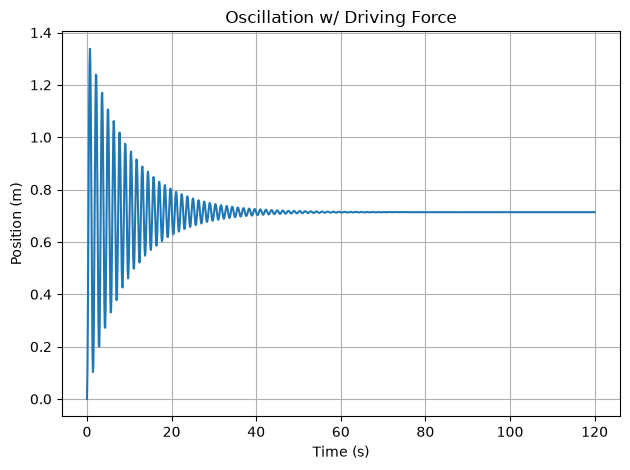

In [186]:
tD = np.linspace(0,120,1200)
xD,vD = (euler_newton(lambda x,t,v: (osc(2,20,x,t,v) + drivingF(100,2,t)),tD,0,0,10))
plt.plot(tD,xD)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Oscillation w/ Driving Force")
plt.tight_layout()
plt.grid()
plt.show()

**Adjusting forcing function for a changing** *$\omega$<sub>d</sub>*  
*Will do this by making $\omega$<sub>d</sub> a function of time*

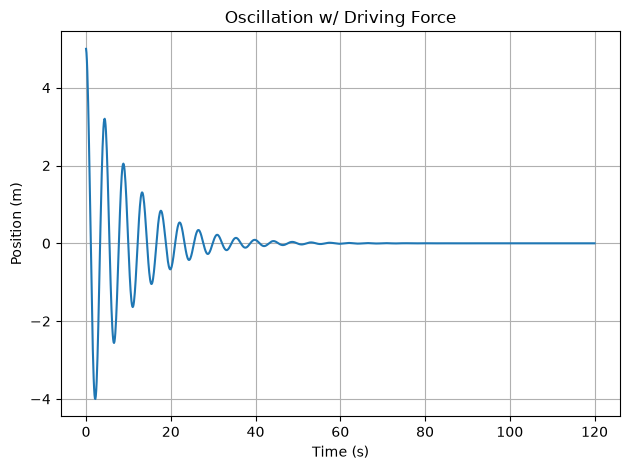

In [187]:
xDW,vDW = (euler_newton(lambda x,t,v: osc(2,20,x,t,v),tD,5,0,10))
plt.plot(tD,xDW)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Oscillation w/ Driving Force")
plt.tight_layout()
plt.grid()
plt.show()